# code_144 · Learning a reusable predictor across generated table tasks

**Book:** section 28.1. A self-contained reusable-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_28_GUIDE.md), [run evidence](../CHAPTER_28_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_144).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. Task inputs are generated. Named pretrained weights, where used, require the explicitly documented one-time acquisition and immutable hash checks. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3544;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3544


<a id="pretraining-context-contract"></a>
 ## Reuse learned weights without hiding the labelled context
 This own small conditional predictor is not TabPFN, TabICL or TabFM. It is pretrained on1,024 generated classification tasks, selected on128 independent development tasks and assessed on128 further tasks. Each task has64 records and2/4/6 active numeric fields; zero-padded values plus availability masks expose different feature counts. Its first32 labelled records form context and the next32 form queries. Task-specific random functions and covariate draws remain whole tasks across splits. A learned query-to-context attention network receives source labels as input and predicts query labels. Pretraining uses2,000 Adam updates at0.002 with16source tasks per update; development Brier selects a checkpoint every100updates. Target inference performs no gradient update. Compare scratch weights, context prevalence, a context-fitted histogram booster and a label-permutation intervention. A changed XOR task family tests a different function prior.


,cohort,predictor,task_count,query_records_per_task,mean_task_Brier
0,New source-family tasks,Scratch weights,128,32,0.250239
1,New source-family tasks,Pretrained frozen context,128,32,0.125250
2,New source-family tasks,Context prevalence,128,32,0.251190
3,New source-family tasks,Per-task histogram booster,128,32,0.133888
4,Changed XOR family,Scratch weights,128,32,0.250490
5,Changed XOR family,Pretrained frozen context,128,32,0.206585
6,Changed XOR family,Context prevalence,128,32,0.238441
7,Changed XOR family,Per-task histogram booster,128,32,0.204307


Context changes outputs, not parameters: 7.21075963973999 True


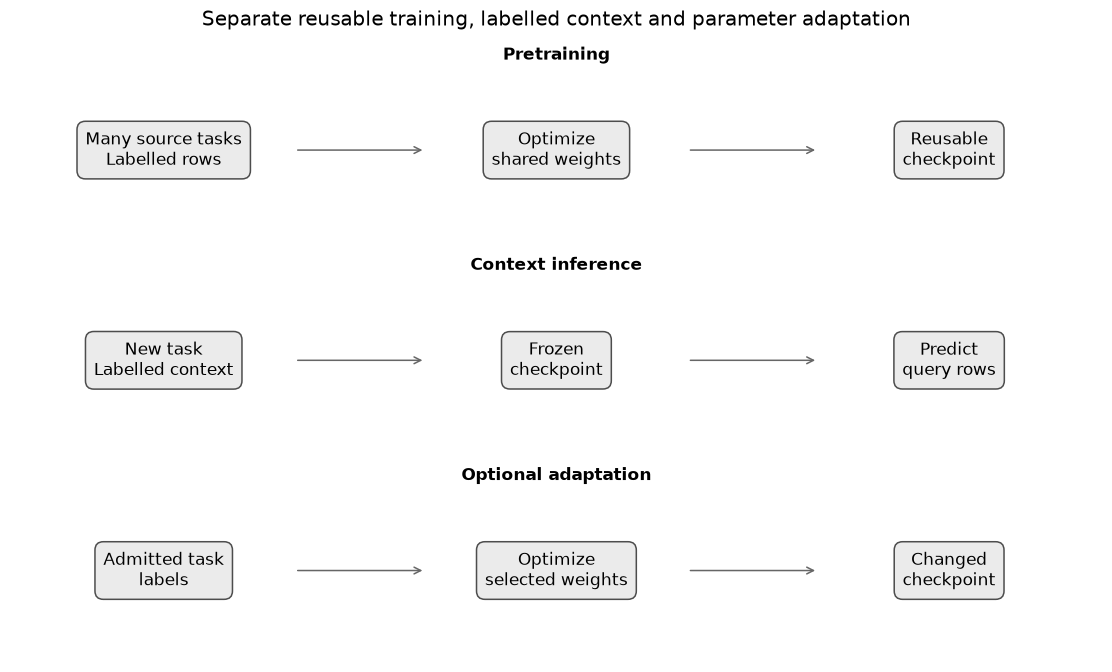

In [2]:
import copy,hashlib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss
def tasks(n,changed=False):
    values=np.zeros((n,64,6),dtype=np.float32);availability=np.zeros_like(values);labels=np.empty((n,64),dtype=np.int64);counts=[]
    for j in range(n):
        width=int(rng.choice([2,4,6]));columns=rng.choice(6,width,replace=False);xx=rng.normal(size=(64,width)).astype(np.float32);weight=rng.normal(size=width);weight/=np.linalg.norm(weight);intercept=rng.normal(0,.4)
        score=2*(xx[:,0]*xx[:,1] if changed else xx@weight)+intercept+rng.normal(0,.4,64);values[j][:,columns]=xx;availability[j][:,columns]=1;labels[j]=(score>0).astype(int);counts.append(width)
    return torch.tensor(np.concatenate([values,availability],2)),torch.tensor(labels),counts
SX,SY,source_width=tasks(1024);DX,DY,_=tasks(128);FX,FY,final_width=tasks(128);OX,OY,_=tasks(128,True)
class ContextPredictor(nn.Module):
    def __init__(self):super().__init__();self.context=nn.Sequential(nn.Linear(13,32),nn.GELU(),nn.Linear(32,32));self.query=nn.Sequential(nn.Linear(12,32),nn.GELU(),nn.Linear(32,32));self.key=nn.Linear(32,32,bias=False);self.value=nn.Linear(32,32,bias=False);self.head=nn.Sequential(nn.Linear(64,32),nn.GELU(),nn.Linear(32,2))
    def forward(self,x,y,query):
        encoded=self.context(torch.cat([x,y.float().unsqueeze(-1)],-1));q=self.query(query);attention=torch.softmax(q@self.key(encoded).transpose(1,2)/np.sqrt(32),-1);return self.head(torch.cat([q,attention@self.value(encoded)],-1))
def probability(model,x,y):
    with torch.no_grad():return model(x[:,:32],y[:,:32],x[:,32:]).softmax(-1)[...,1].numpy()
model=ContextPredictor();scratch=copy.deepcopy(model);optimizer=torch.optim.Adam(model.parameters(),lr=.002);best=np.inf;history=[]
for step in range(2000):
    ids=torch.tensor(rng.choice(1024,16,replace=False));optimizer.zero_grad();logits=model(SX[ids,:32],SY[ids,:32],SX[ids,32:]);loss=nn.functional.cross_entropy(logits.reshape(-1,2),SY[ids,32:].reshape(-1));loss.backward();optimizer.step()
    if (step+1)%100==0:
        score=float(np.mean((probability(model,DX,DY)-DY[:,32:].numpy())**2));history.append([step+1,score])
        if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step+1
model.load_state_dict(state)
def digest(model):return hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in model.state_dict().values())).hexdigest()
before=digest(model);prediction=probability(model,FX,FY);after=digest(model);assert before==after
perm=torch.tensor(rng.permutation(32))
with torch.no_grad():original=model(FX[:4,:32],FY[:4,:32],FX[:4,32:]);permuted=model(FX[:4,:32][:,perm],FY[:4,:32][:,perm],FX[:4,32:]);torch.testing.assert_close(original,permuted,atol=2e-6,rtol=2e-6);flipped=model(FX[:4,:32],1-FY[:4,:32],FX[:4,32:])
label_effect=float((flipped-original).abs().max());assert label_effect>1e-4
rows=[]
for cohort,x,y in [('New source-family tasks',FX,FY),('Changed XOR family',OX,OY)]:
    target=y[:,32:].numpy();probs={'Scratch weights':probability(scratch,x,y),'Pretrained frozen context':probability(model,x,y),'Context prevalence':np.repeat(y[:,:32].numpy().mean(1)[:,None],32,1)};trees=[]
    for j in range(len(x)):
        # Booster fits only this task's admitted context, with fixed native settings.
        tree=HistGradientBoostingClassifier(max_iter=40,max_leaf_nodes=7,min_samples_leaf=4,learning_rate=.1,l2_regularization=1,early_stopping=False,random_state=SEED).fit(x[j,:32].numpy(),y[j,:32].numpy());trees.append(tree.predict_proba(x[j,32:].numpy())[:,1])
    probs['Per-task histogram booster']=np.array(trees)
    for name,p in probs.items():rows.append({'cohort':cohort,'predictor':name,'task_count':len(x),'query_records_per_task':32,'mean_task_Brier':float(np.mean((p-target)**2))})
context_sizes=[4,8,16,32];curve=[]
for size in context_sizes:
    with torch.no_grad():p=model(FX[:,:size],FY[:,:size],FX[:,32:]).softmax(-1)[...,1].numpy()
    curve.append(float(np.mean((p-FY[:,32:].numpy())**2)))
RESULTS.update(source_tasks=1024,development_tasks=128,final_tasks=128,changed_family_tasks=128,records_per_task=64,pretraining_updates=2000,pretraining_rate=.002,selected_update=best_step,development_Brier=best,parameters=sum(p.numel() for p in model.parameters()),weights_unchanged_by_context_inference=before==after,context_label_logit_max_effect=label_effect,comparisons=rows,context_sizes=context_sizes,context_size_Brier=curve,final_width_counts={str(w):final_width.count(w) for w in [2,4,6]});display(pd.DataFrame(rows));print('Context changes outputs, not parameters:',label_effect,before==after)
fig,axes=plt.subplots(3,1,figsize=(10,6));lanes=[('Pretraining',['Many source tasks\nLabelled rows','Optimize\nshared weights','Reusable\ncheckpoint']),('Context inference',['New task\nLabelled context','Frozen\ncheckpoint','Predict\nquery rows']),('Optional adaptation',['Admitted task\nlabels','Optimize\nselected weights','Changed\ncheckpoint'])]
for ax,(title,labels) in zip(axes,lanes):
    ax.axis('off');ax.text(.5,.9,title,ha='center',weight='bold',transform=ax.transAxes)
    for position,label in zip([.14,.5,.86],labels):ax.text(position,.45,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=.5','facecolor':'.92','edgecolor':'.3'})
    for lo,hi in [(.26,.38),(.62,.74)]:ax.annotate('',xy=(hi,.45),xytext=(lo,.45),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'.4'})
fig.suptitle('Separate reusable training, labelled context and parameter adaptation');plt.show()


<a id="reuse-and-prior-limits"></a>
 ## An amortized learning rule inherits its task distribution
 All1024source functions differ from development/final functions. A padding mask represents absent columns rather than pretending an absent value is a measured zero. The reference remains a fixed maximum-width numeric model, not a universal semantic schema encoder. Context is32labelled rows on each new task; zero gradient updates does not mean zero supervision. Context row permutation preserves predictions within float32 arithmetic tolerance; changing its labels affects actual predictions, while byte hashes verify unchanged weights. The fixed booster receives the same context but fits parameters separately. The XOR cohort changes the pretraining function prior and remains assessment-only. No checkpoint in this notebook is a named public foundation model, no benchmark speedup is claimed, and these generated task outcomes do not validate real-site transfer.


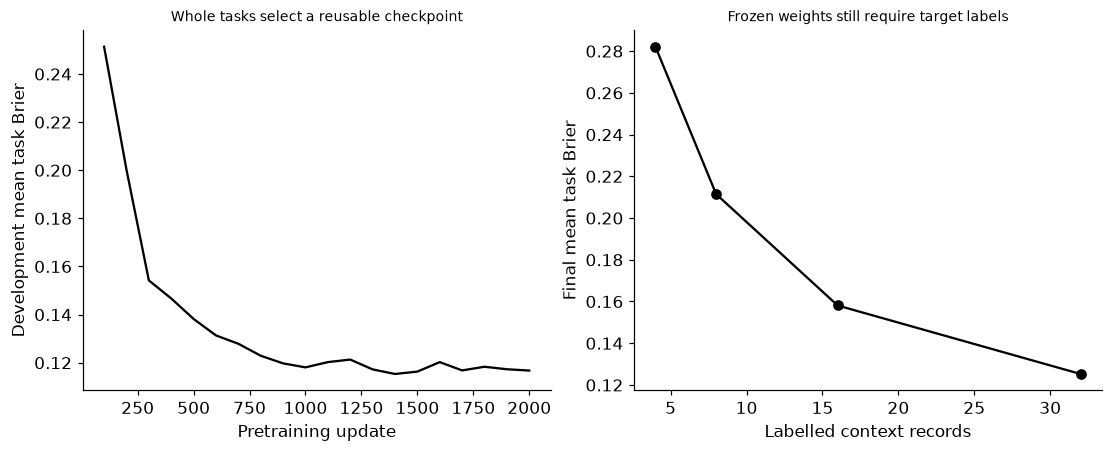

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));h=np.array(history);axes[0].plot(h[:,0],h[:,1],color='black');axes[0].set(xlabel='Pretraining update',ylabel='Development mean task Brier',title='Whole tasks select a reusable checkpoint');axes[1].plot(context_sizes,curve,'o-',color='black');axes[1].set(xlabel='Labelled context records',ylabel='Final mean task Brier',title='Frozen weights still require target labels');plt.show()
assert all(np.isfinite(row['mean_task_Brier']) for row in rows)


In [4]:
summary={'example_id':'code_144','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual cross-task synthetic pretraining', 'separate frozen labelled-context inference', 'heterogeneous feature-count masks', 'task-level development and assessment', 'parameter invariance and context permutation checks'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual cross-task synthetic pretraining", "separate frozen labelled-context inference", "heterogeneous feature-count masks", "task-level development and assessment", "parameter invariance and context permutation checks"], "elapsed_seconds": 3.324, "example_id": "code_144", "hardware": "Darwin arm64 CPU", "results": {"changed_family_tasks": 128, "comparisons": [{"cohort": "New source-family tasks", "mean_task_Brier": 0.2502388543370181, "predictor": "Scratch weights", "query_records_per_task": 32, "task_count": 128}, {"cohort": "New source-family tasks", "mean_task_Brier": 0.1252496930031552, "predictor": "Pretrained frozen context", "query_records_per_task": 32, "task_count": 128}, {"cohort": "New source-family tasks", "mean_task_Brier": 0.251190185546875, "predictor": "Context prevalence", "query_records_per_task": 32, "task_count": 128}, {"cohort": "New source-family tasks", "mean_task_Brier": 0.13388829114196588, "predictor": "Per-t